In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:

df = pd.read_csv("hotel_bookings.csv")

In [3]:

df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)

df[[
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "arrival_date"
]].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


In [4]:

cutoff_70 = df["arrival_date"].quantile(0.70)
cutoff_85 = df["arrival_date"].quantile(0.85)

train = df[df["arrival_date"] <= cutoff_70].copy()
validation = df[
    (df["arrival_date"] > cutoff_70) &
    (df["arrival_date"] <= cutoff_85)
].copy()
test = df[df["arrival_date"] > cutoff_85].copy()

print("Cutoffs:", cutoff_70.date(), cutoff_85.date())
print("Split sizes:", len(train), len(validation), len(test))

Cutoffs: 2017-02-10 2017-05-22
Split sizes: 83629 18048 17713


In [5]:
df.info()




<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   hotel                           119390 non-null  str           
 1   is_canceled                     119390 non-null  int64         
 2   lead_time                       119390 non-null  int64         
 3   arrival_date_year               119390 non-null  int64         
 4   arrival_date_month              119390 non-null  str           
 5   arrival_date_week_number        119390 non-null  int64         
 6   arrival_date_day_of_month       119390 non-null  int64         
 7   stays_in_weekend_nights         119390 non-null  int64         
 8   stays_in_week_nights            119390 non-null  int64         
 9   adults                          119390 non-null  int64         
 10  children                        119386 non-null  float64       
 11

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01


In [7]:
df.describe()







,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,arrival_date
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,...,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,...,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363,2016-08-28 16:39:45.727447
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000,2015-07-01 00:00:00
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000,2016-03-13 00:00:00
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000,2016-09-06 00:00:00
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000,2017-03-18 00:00:00
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,...,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000,2017-08-31 00:00:00
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,...,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798,NaN


In [8]:
df.duplicated().sum()







np.int64(31994)

In [9]:
duplicates = df[df.duplicated(keep=False)]
duplicates.sort_values(list(df.columns)).head(20)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
40772,City Hotel,0,0,2015,August,32,7,0,2,2,...,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09,2015-08-07
40802,City Hotel,0,0,2015,August,32,7,0,2,2,...,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09,2015-08-07
40821,City Hotel,0,0,2015,August,32,8,0,1,2,...,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09,2015-08-08
40838,City Hotel,0,0,2015,August,32,8,0,1,2,...,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09,2015-08-08
76792,City Hotel,0,0,2015,August,33,10,1,0,2,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11,2015-08-10
76793,City Hotel,0,0,2015,August,33,10,1,0,2,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11,2015-08-10
76794,City Hotel,0,0,2015,August,33,10,1,0,2,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11,2015-08-10
41067,City Hotel,0,0,2015,August,33,11,0,1,1,...,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12,2015-08-11
41073,City Hotel,0,0,2015,August,33,11,0,1,1,...,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12,2015-08-11
41071,City Hotel,0,0,2015,August,33,11,0,1,2,...,NaN,NaN,0,Transient,80.0,0,0,Check-Out,2015-08-12,2015-08-11


In [10]:
target_summary = pd.DataFrame({
    "count": df["is_canceled"].value_counts(),
    "percentage": df["is_canceled"].value_counts(normalize=True).mul(100).round(1)
})

target_summary

,count,percentage
is_canceled,,
0,75166,63.0
1,44224,37.0


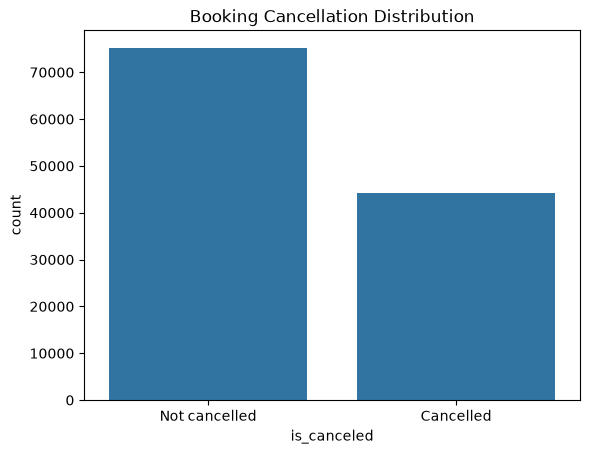

In [11]:
sns.countplot(data=df, x="is_canceled")
plt.xticks([0, 1], ["Not cancelled", "Cancelled"])
plt.title("Booking Cancellation Distribution")
plt.show()

In [12]:
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

features = [
    "lead_time",
    "adr",
    "total_of_special_requests",
    "total_nights"
]

df.groupby("is_canceled")[features].agg(["median", "mean"]).round(2)

lead_time            adr         total_of_special_requests        \
               median    mean median    mean                    median  mean   
is_canceled                                                                    
0                45.0   79.98   92.5   99.99                       1.0  0.71   
1               113.0  144.85   96.2  104.96                       0.0  0.33   

            total_nights        
                  median  mean  
is_canceled                     
0                    3.0  3.39  
1                    3.0  3.49

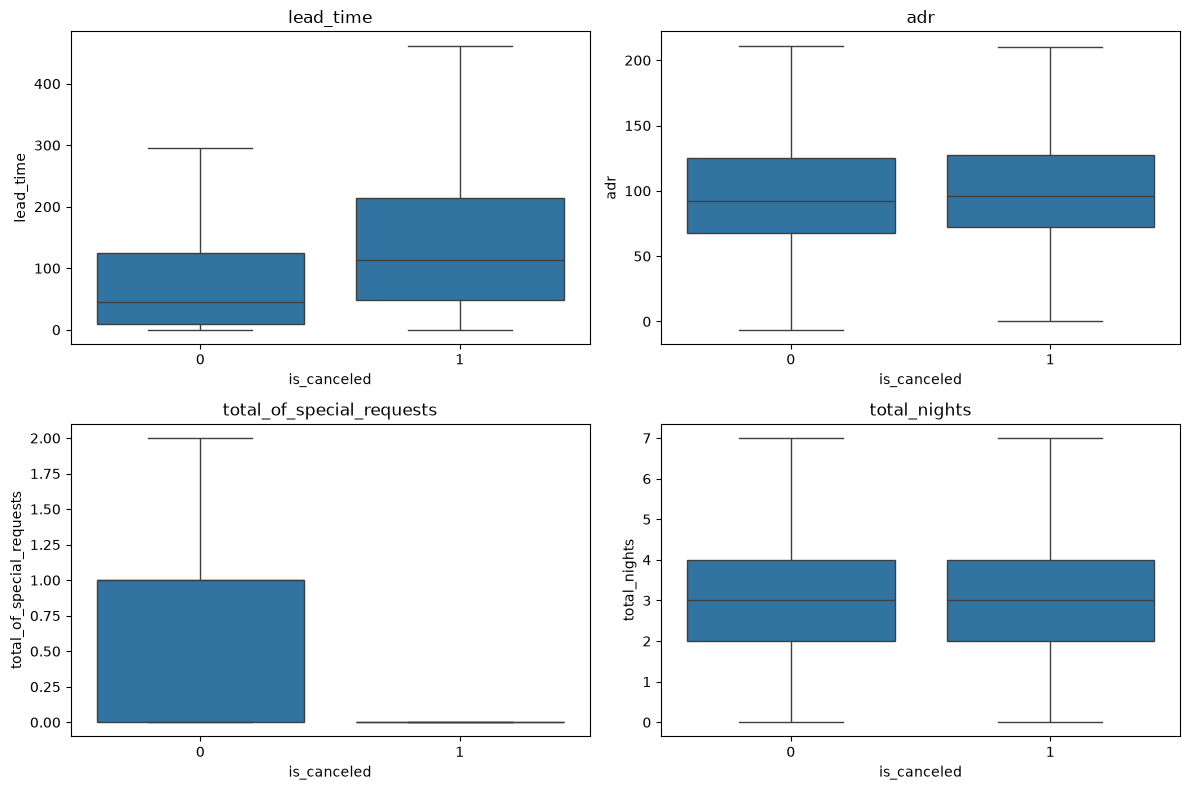

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="is_canceled",
        y=feature,
        showfliers=False,
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

In [14]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)


company     112593
agent        16340
country        488
children         4
dtype: int64

In [15]:

for name, data in [
    ("Train (raw)", train),
    ("Validation (raw)", validation),
    ("Test (raw)", test),
]:
    print(name)
    print(data[["country", "children", "agent", "company"]].isna().sum())

Train (raw)
country       434
children        4
agent       11815
company     78635
dtype: int64
Validation (raw)
country        54
children        0
agent        2800
company     16852
dtype: int64
Test (raw)
country         0
children        0
agent        1725
company     17106
dtype: int64


In [16]:
# Validity handling is intentionally performed after missing-value
# imputation below, so the guest total uses the imputed children values.

In [17]:
cancellation_rate = (
    df.groupby("deposit_type")["is_canceled"]
      .mean()
      .mul(100)
      .round(1)
)

print(cancellation_rate)

deposit_type
No Deposit    28.4
Non Refund    99.4
Refundable    22.2
Name: is_canceled, dtype: float64


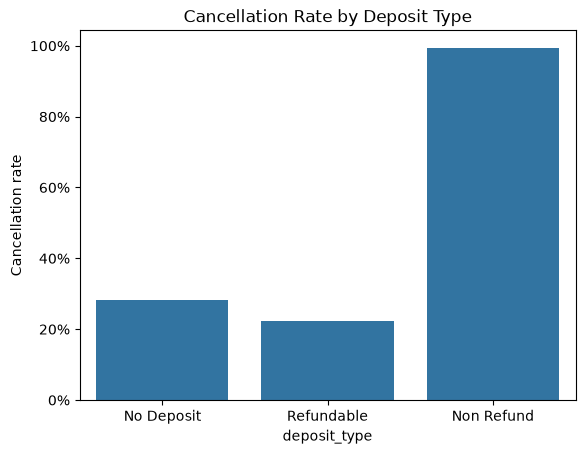

In [18]:
sns.barplot(
    data=df,
    x="deposit_type",
    y="is_canceled",
    errorbar=None
)

plt.ylabel("Cancellation rate")
plt.title("Cancellation Rate by Deposit Type")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)
plt.show()

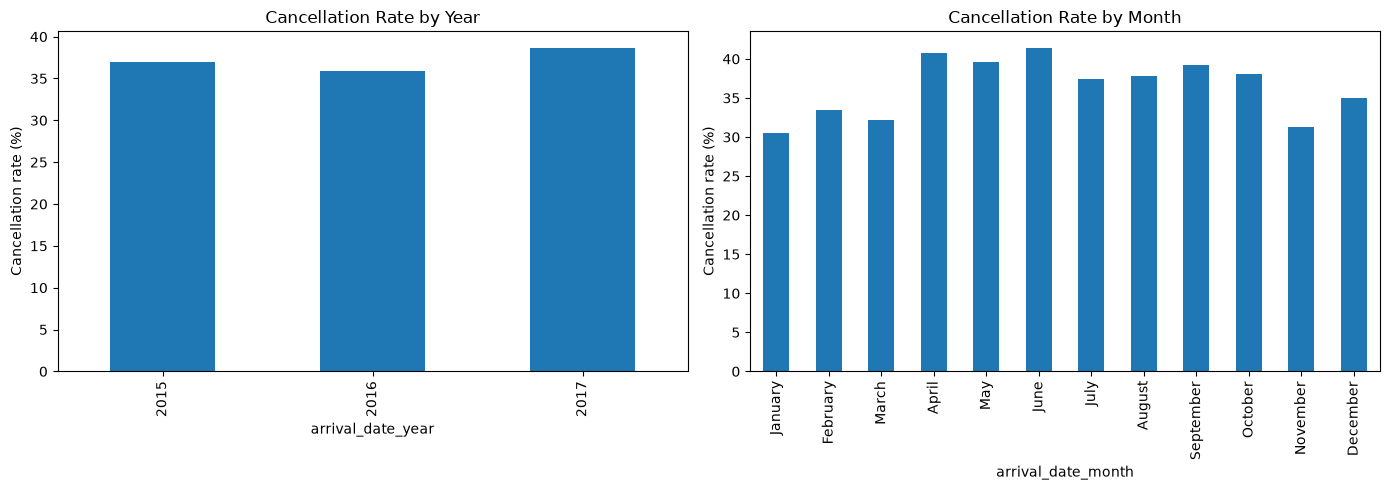

In [19]:
yearly_rate = (
    df.groupby("arrival_date_year")["is_canceled"]
      .mean().mul(100).round(1)
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_rate = (
    df.groupby("arrival_date_month")["is_canceled"]
      .mean().mul(100)
      .reindex(month_order)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

yearly_rate.plot(kind="bar", ax=axes[0], title="Cancellation Rate by Year")
monthly_rate.plot(kind="bar", ax=axes[1], title="Cancellation Rate by Month")

axes[0].set_ylabel("Cancellation rate (%)")
axes[1].set_ylabel("Cancellation rate (%)")
plt.tight_layout()
plt.show()

In [20]:

country_mode = train["country"].mode().iat[0]
children_mode = train["children"].mode().iat[0]

# Check the unique non-missing raw agent IDs before using 0 as a placeholder.
unique_agents = df["agent"].dropna().unique()
assert 0 not in unique_agents, "Agent ID 0 already exists"

print("Training country mode:", country_mode)
print("Training children mode:", children_mode)
print("Agent placeholder 0 is available")


Training country mode: PRT
Training children mode: 0.0
Agent placeholder 0 is available


In [21]:

def preprocess_missing(data):
    data = data.copy()

    
    data["country"] = data["country"].fillna(country_mode)
    data["children"] = data["children"].fillna(children_mode).astype("Int64")

    data["booked_via_agent"] = data["agent"].notna().astype(int)
    data["booked_via_company"] = data["company"].notna().astype(int)

    
    data["agent"] = data["agent"].fillna(0).astype("Int64")
    data["company"] = (
        data["company"]
        .astype("Int64")
        .astype("string")
        .fillna("None")
    )

    return data

train = preprocess_missing(train)
validation = preprocess_missing(validation)
test = preprocess_missing(test)

In [22]:
# STEP 6 — After imputation, remove impossible zero-guest bookings and
# retain ambiguous zero-night bookings with an explicit indicator.
def handle_invalid_rows(data):
    data = data.copy()

    data["total_guests"] = data[["adults", "children", "babies"]].sum(axis=1)
    data = data.loc[data["total_guests"] > 0].copy()

    data["total_nights"] = (
        data["stays_in_weekend_nights"] +
        data["stays_in_week_nights"]
    )
    data["zero_night_stay"] = data["total_nights"].eq(0).astype(int)

    return data


sizes_before_validity_check = {
    "Train": len(train),
    "Validation": len(validation),
    "Test": len(test),
}

train = handle_invalid_rows(train)
validation = handle_invalid_rows(validation)
test = handle_invalid_rows(test)

# STEP 7 — Validate both missing-value and validity handling.
columns_checked = [
    "country", "children", "agent", "company", "zero_night_stay"
]

for name, data in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test),
]:
    missing_after = data[columns_checked].isna().sum()
    removed = sizes_before_validity_check[name] - len(data)
    remaining_zero_guests = (
        data[["adults", "children", "babies"]].sum(axis=1) == 0
    ).sum()

    print(f"{name}:\n{missing_after}")
    print(
        f"Removed {removed} zero-guest rows; "
        f"retained {data['zero_night_stay'].sum()} zero-night rows\n"
    )

    assert missing_after.sum() == 0, f"Missing values remain in {name}"
    assert remaining_zero_guests == 0, f"Zero-guest rows remain in {name}"

Train:
country            0
children           0
agent              0
company            0
zero_night_stay    0
dtype: int64
Removed 122 zero-guest rows; retained 570 zero-night rows

Validation:
country            0
children           0
agent              0
company            0
zero_night_stay    0
dtype: int64
Removed 44 zero-guest rows; retained 47 zero-night rows

Test:
country            0
children           0
agent              0
company            0
zero_night_stay    0
dtype: int64
Removed 14 zero-guest rows; retained 28 zero-night rows



In [23]:
# Engineered features and ADR clipping. Rules are learned from the
# cleaned training split only, then applied unchanged to validation/test.
adr_floor = 0
adr_cap = train["adr"].quantile(0.999)

lead_time_bins = [-1, 7, 30, 90, 180, np.inf]
lead_time_labels = ["0-7", "8-30", "31-90", "91-180", "181+"]

print("Training ADR cap (99.9th percentile):", round(adr_cap, 2))


def add_engineered_features(data):
    data = data.copy()

    clipped_low = data["adr"].lt(adr_floor).sum()
    clipped_high = data["adr"].gt(adr_cap).sum()
    data["adr"] = data["adr"].clip(lower=adr_floor, upper=adr_cap)

    data["has_special_requests"] = (
        data["total_of_special_requests"].gt(0).astype(int)
    )
    data["lead_time_bucket"] = pd.cut(
        data["lead_time"],
        bins=lead_time_bins,
        labels=lead_time_labels,
    ).astype("string")

    return data, clipped_low, clipped_high


engineered_cols = [
    "total_guests",
    "total_nights",
    "has_special_requests",
    "lead_time_bucket",
]

train, train_low, train_high = add_engineered_features(train)
validation, val_low, val_high = add_engineered_features(validation)
test, test_low, test_high = add_engineered_features(test)

for name, data, n_low, n_high in [
    ("Train", train, train_low, train_high),
    ("Validation", validation, val_low, val_high),
    ("Test", test, test_low, test_high),
]:
    missing = data[engineered_cols + ["adr"]].isna().sum().sum()
    print(
        f"{name}: ADR clipped <0={n_low}, >cap={n_high}; "
        f"adr range {data['adr'].min():.2f} to {data['adr'].max():.2f}; "
        f"engineered missing={missing}"
    )
    print(data["lead_time_bucket"].value_counts().sort_index())
    print()
    assert missing == 0, f"Engineered features missing in {name}"
    assert data["adr"].min() >= adr_floor
    assert data["adr"].max() <= adr_cap
    for col in engineered_cols:
        assert col in data.columns, f"{col} missing from {name}"


Training ADR cap (99.9th percentile): 303.42
Train: ADR clipped <0=0, >cap=84; adr range 0.00 to 303.42; engineered missing=0
lead_time_bucket
0-7       15355
181+      16572
31-90     21692
8-30      13751
91-180    16137
Name: count, dtype: Int64

Validation: ADR clipped <0=1, >cap=10; adr range 0.00 to 303.42; engineered missing=0
lead_time_bucket
0-7       2570
181+      2343
31-90     5043
8-30      3093
91-180    4955
Name: count, dtype: Int64

Test: ADR clipped <0=0, >cap=164; adr range 0.00 to 303.42; engineered missing=0
lead_time_bucket
0-7       1710
181+      5766
31-90     2794
8-30      2101
91-180    5328
Name: count, dtype: Int64



In [24]:
total_guests = (
    df[["adults", "children", "babies"]]
    .fillna(0)
    .sum(axis=1)
)

total_nights = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

zero_guests = total_guests == 0
zero_nights = total_nights == 0

print("Zero-guest rows:", zero_guests.sum())
print("Zero-night rows:", zero_nights.sum())

print(
    "Zero-guest cancellation rate:",
    df.loc[zero_guests, "is_canceled"].mean() * 100
)

print(
    "Zero-night cancellation rate:",
    df.loc[zero_nights, "is_canceled"].mean() * 100
)

Zero-guest rows: 180
Zero-night rows: 715
Zero-guest cancellation rate: 13.88888888888889
Zero-night cancellation rate: 4.895104895104895


In [25]:
df.loc[zero_guests | zero_nights].head(20)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,total_nights
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01,0
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,NaN,0,Transient,0.0,0,2,Check-Out,2015-07-06,2015-07-06,0
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-06,2015-07-06,0
196,Resort Hotel,0,8,2015,July,28,7,0,0,2,...,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-07,2015-07-07,0
197,Resort Hotel,0,8,2015,July,28,7,0,0,2,...,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-07,2015-07-07,0
459,Resort Hotel,0,6,2015,July,29,17,0,0,2,...,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-17,2015-07-17,0
568,Resort Hotel,0,0,2015,July,30,20,0,0,1,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-20,2015-07-20,0
569,Resort Hotel,0,0,2015,July,30,20,0,0,2,...,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-20,2015-07-20,0
618,Resort Hotel,0,16,2015,July,30,23,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-23,2015-07-23,0


In [26]:
# STEP 8 — Learn category groups from the cleaned TRAINING split only.
# Country: top 9 + Other.
# Agent: top 8 actual IDs + None + Other.
# Company: top 8 actual IDs + None + Other.
top_9_countries = train["country"].value_counts().nlargest(9).index
top_8_agents = (
    train.loc[train["agent"].ne(0), "agent"]
    .value_counts()
    .nlargest(8)
    .index
)
top_8_companies = (
    train.loc[train["company"].ne("None"), "company"]
    .value_counts()
    .nlargest(8)
    .index
)


def add_category_groups(data):
    data = data.copy()

    data["country_group"] = data["country"].where(
        data["country"].isin(top_9_countries),
        "Other",
    )

    data["agent_group"] = data["agent"].astype("string")
    other_agent = ~data["agent"].isin(top_8_agents) & data["agent"].ne(0)
    data.loc[other_agent, "agent_group"] = "Other"
    data.loc[data["agent"].eq(0), "agent_group"] = "None"

    data["company_group"] = data["company"].astype("string")
    other_company = (
        ~data["company"].isin(top_8_companies)
        & data["company"].ne("None")
    )
    data.loc[other_company, "company_group"] = "Other"

    return data


train = add_category_groups(train)
validation = add_category_groups(validation)
test = add_category_groups(test)

In [27]:
# STEP 9 — Validate the grouped categorical features.
grouped_cols = ["country_group", "agent_group", "company_group"]

for name, data in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test),
]:
    print(
        name,
        "country groups:", data["country_group"].nunique(),
        "agent groups:", data["agent_group"].nunique(),
        "company groups:", data["company_group"].nunique(),
        "grouped missing values:",
        data[grouped_cols].isna().sum().sum(),
    )

print("\nTraining country groups:")
print(train["country_group"].value_counts())
print("\nTraining agent groups:")
print(train["agent_group"].value_counts())
print("\nTraining company groups:")
print(train["company_group"].value_counts())

Train country groups: 10 agent groups: 10 company groups: 10 grouped missing values: 0
Validation country groups: 10 agent groups: 10 company groups: 8 grouped missing values: 0
Test country groups: 10 agent groups: 10 company groups: 8 grouped missing values: 0

Training country groups:
country_group
PRT      37992
Other    12785
GBR       7324
FRA       6950
ESP       6327
DEU       4554
ITA       2690
IRL       2063
BEL       1420
BRA       1402
Name: count, dtype: int64

Training agent groups:
agent_group
Other    25025
9        20076
None     11777
240       9607
1         6967
6         2588
7         2329
14        2130
250       1826
28        1182
Name: count, dtype: Int64

Training company groups:
company_group
None     78531
Other     2702
40         784
223        555
67         267
45         185
281        131
174        125
153        114
233        113
Name: count, dtype: Int64


In [28]:

train[[
    "country", "country_group", "children",
    "agent", "agent_group", "company", "company_group",
    "booked_via_agent", "booked_via_company",
]].head()

,country,country_group,children,agent,agent_group,company,company_group,booked_via_agent,booked_via_company
0,PRT,PRT,0,0,None,None,None,0,0
1,PRT,PRT,0,0,None,None,None,0,0
2,GBR,GBR,0,0,None,None,None,0,0
3,GBR,GBR,0,304,Other,None,None,1,0
4,GBR,GBR,0,240,240,None,None,1,0


In [29]:
# STEP 10 — Remove leakage columns before encoding and model fitting.
# reserved_room_type is intentionally retained.
columns_to_drop = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
]

train = train.drop(columns=columns_to_drop)
validation = validation.drop(columns=columns_to_drop)
test = test.drop(columns=columns_to_drop)

In [30]:
print([col for col in columns_to_drop if col in train.columns])
print("reserved_room_type" in train.columns)

[]
True


In [31]:

assert train["arrival_date"].max() < validation["arrival_date"].min()
assert validation["arrival_date"].max() < test["arrival_date"].min()

split_sizes = pd.Series({
    "train": len(train),
    "validation": len(validation),
    "test": len(test),
})
print((split_sizes / split_sizes.sum() * 100).round(2))

train         70.05
validation    15.10
test          14.85
dtype: float64


In [32]:
target = "is_canceled"

# Remove non-model fields and original high-cardinality fields that were grouped
exclude_features = [
    target,
    "arrival_date",  # used for splitting, not directly accepted by the model
    "country",       # replaced by country_group
    "agent",         # replaced by agent_group
    "company",       # replaced by company_group
]

X_train = train.drop(columns=exclude_features)
y_train = train[target]

X_validation = validation.drop(columns=exclude_features)
y_validation = validation[target]

X_test = test.drop(columns=exclude_features)
y_test = test[target]

In [33]:
categorical_features = [
    "hotel",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "customer_type",
    "country_group",
    "agent_group",
    "company_group",
    "lead_time_bucket",
]

numeric_features = [
    column for column in X_train.columns
    if column not in categorical_features
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'booked_via_agent', 'booked_via_company', 'total_guests', 'total_nights', 'zero_night_stay', 'has_special_requests']
Categorical features: ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'country_group', 'agent_group', 'company_group', 'lead_time_bucket']


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [35]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    solver="saga",
    max_iter=5000,
    random_state=42
)

logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", logistic_model)
])

In [36]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['hotel','lead_time','arrival_date_year',...,'country_group','agent_group', 'company_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [37]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

validation_predictions = logistic_pipeline.predict(X_validation)
validation_probabilities = logistic_pipeline.predict_proba(X_validation)[:, 1]

print(classification_report(y_validation, validation_predictions))
print("Confusion matrix:")
print(confusion_matrix(y_validation, validation_predictions))

print("ROC-AUC:", roc_auc_score(
    y_validation, validation_probabilities
))
print("PR-AUC:", average_precision_score(
    y_validation, validation_probabilities
))
print("Log loss:", log_loss(
    y_validation, validation_probabilities
))
print("Brier score:", brier_score_loss(
    y_validation, validation_probabilities
))

              precision    recall  f1-score   support

           0       0.89      0.77      0.83     10920
           1       0.71      0.86      0.78      7084

    accuracy                           0.81     18004
   macro avg       0.80      0.81      0.80     18004
weighted avg       0.82      0.81      0.81     18004

Confusion matrix:
[[8448 2472]
 [1022 6062]]
ROC-AUC: 0.9026448900478404
PR-AUC: 0.865080488544973
Log loss: 0.41545672357961116
Brier score: 0.13576687227462944


In [38]:
from sklearn.tree import DecisionTreeClassifier

# Light constraint: a full-depth tree overfits on ~83k rows.
# Stronger search is reserved for random forest and boosting.
tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=10,
    random_state=42,
)

tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", tree_model),
])

tree_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['hotel','lead_time','arrival_date_year',...,'country_group','agent_group', 'company_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [39]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)

tree_validation_predictions = tree_pipeline.predict(X_validation)
tree_validation_probabilities = tree_pipeline.predict_proba(X_validation)[:, 1]

print(classification_report(y_validation, tree_validation_predictions))
print("Confusion matrix:")
print(confusion_matrix(y_validation, tree_validation_predictions))

print("ROC-AUC:", roc_auc_score(
    y_validation, tree_validation_probabilities
))
print("PR-AUC:", average_precision_score(
    y_validation, tree_validation_probabilities
))
print("Log loss:", log_loss(
    y_validation, tree_validation_probabilities
))
print("Brier score:", brier_score_loss(
    y_validation, tree_validation_probabilities
))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85     10920
           1       0.79      0.72      0.75      7084

    accuracy                           0.81     18004
   macro avg       0.81      0.80      0.80     18004
weighted avg       0.81      0.81      0.81     18004

Confusion matrix:
[[9588 1332]
 [2009 5075]]
ROC-AUC: 0.8960501390431515
PR-AUC: 0.8309185703184252
Log loss: 0.4169309802541374
Brier score: 0.1292289737410681


In [40]:
from sklearn.ensemble import RandomForestClassifier

# Same depth as the single tree so the lift is bagging, not a deeper model.
# Optuna search comes after the gradient-boosting baseline is also in place.
forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

forest_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", forest_model),
])

forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['hotel','lead_time','arrival_date_year',...,'country_group','agent_group', 'company_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [41]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)

forest_validation_predictions = forest_pipeline.predict(X_validation)
forest_validation_probabilities = forest_pipeline.predict_proba(X_validation)[:, 1]

print(classification_report(y_validation, forest_validation_predictions))
print("Confusion matrix:")
print(confusion_matrix(y_validation, forest_validation_predictions))

print("ROC-AUC:", roc_auc_score(
    y_validation, forest_validation_probabilities
))
print("PR-AUC:", average_precision_score(
    y_validation, forest_validation_probabilities
))
print("Log loss:", log_loss(
    y_validation, forest_validation_probabilities
))
print("Brier score:", brier_score_loss(
    y_validation, forest_validation_probabilities
))

              precision    recall  f1-score   support

           0       0.82      0.91      0.86     10920
           1       0.83      0.70      0.76      7084

    accuracy                           0.82     18004
   macro avg       0.82      0.80      0.81     18004
weighted avg       0.82      0.82      0.82     18004

Confusion matrix:
[[9886 1034]
 [2155 4929]]
ROC-AUC: 0.9057605244134748
PR-AUC: 0.8699106655695844
Log loss: 0.4025346014019399
Brier score: 0.12810319632857559


In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import FunctionTransformer


def to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return X


# Shallow trees: boosting's counterpart to the depth-10 bagged forest.
# Histogram GBM is sklearn's large-data gradient boosting implementation.
# Optuna will search depth, learning rate, and iteration count next.
boost_model = HistGradientBoostingClassifier(
    max_depth=6,
    learning_rate=0.1,
    max_iter=200,
    class_weight="balanced",
    random_state=42,
)

boost_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("to_dense", FunctionTransformer(to_dense, accept_sparse=True)),
    ("model", boost_model),
])

boost_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('to_dense', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['hotel','lead_time','arrival_date_year',...,'country_group','agent_group', 'company_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [44]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)

boost_validation_predictions = boost_pipeline.predict(X_validation)
boost_validation_probabilities = boost_pipeline.predict_proba(X_validation)[:, 1]

print(classification_report(y_validation, boost_validation_predictions))
print("Confusion matrix:")
print(confusion_matrix(y_validation, boost_validation_predictions))

print("ROC-AUC:", roc_auc_score(
    y_validation, boost_validation_probabilities
))
print("PR-AUC:", average_precision_score(
    y_validation, boost_validation_probabilities
))
print("Log loss:", log_loss(
    y_validation, boost_validation_probabilities
))
print("Brier score:", brier_score_loss(
    y_validation, boost_validation_probabilities
))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85     10920
           1       0.75      0.85      0.79      7084

    accuracy                           0.83     18004
   macro avg       0.82      0.83      0.82     18004
weighted avg       0.84      0.83      0.83     18004

Confusion matrix:
[[8876 2044]
 [1067 6017]]
ROC-AUC: 0.9192415956197011
PR-AUC: 0.8842879123070189
Log loss: 0.35742648126852494
Brier score: 0.11798793608007702


In [45]:
import optuna
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import FunctionTransformer

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Time-ordered training rows only. Validation and test stay out of the search.
cv_order = train.sort_values("arrival_date").index
X_cv = X_train.loc[cv_order]
y_cv = y_train.loc[cv_order]
time_cv = TimeSeriesSplit(n_splits=3)
N_TRIALS = 20


def to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return X


def mean_cv_roc_auc(pipeline):
    scores = []
    for train_idx, fold_idx in time_cv.split(X_cv):
        model = clone(pipeline)
        model.fit(X_cv.iloc[train_idx], y_cv.iloc[train_idx])
        proba = model.predict_proba(X_cv.iloc[fold_idx])[:, 1]
        scores.append(roc_auc_score(y_cv.iloc[fold_idx], proba))
    return float(np.mean(scores))

print("CV rows:", len(X_cv))
print("TimeSeriesSplit folds:", time_cv.get_n_splits())
print("Optuna trials per model:", N_TRIALS)

CV rows: 83507
TimeSeriesSplit folds: 3
Optuna trials per model: 20


C:\Users\ab_bl\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)


def forest_objective(trial):
    model = RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 300),
        max_depth=trial.suggest_int("max_depth", 6, 18),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
        max_features=trial.suggest_categorical(
            "max_features", ["sqrt", "log2", 0.5]
        ),
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", model),
    ])
    return mean_cv_roc_auc(pipeline)


forest_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    study_name="random_forest",
)
forest_study.optimize(forest_objective, n_trials=N_TRIALS, show_progress_bar=True)

print("Best RF CV ROC-AUC:", round(forest_study.best_value, 4))
print("Best RF params:", forest_study.best_params)

forest_tuned_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        **forest_study.best_params,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])
forest_tuned_pipeline.fit(X_train, y_train)

forest_tuned_pred = forest_tuned_pipeline.predict(X_validation)
forest_tuned_proba = forest_tuned_pipeline.predict_proba(X_validation)[:, 1]

print(classification_report(y_validation, forest_tuned_pred))
print("Confusion matrix:")
print(confusion_matrix(y_validation, forest_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_validation, forest_tuned_proba))
print("PR-AUC:", average_precision_score(y_validation, forest_tuned_proba))
print("Log loss:", log_loss(y_validation, forest_tuned_proba))
print("Brier score:", brier_score_loss(y_validation, forest_tuned_proba))

Best trial: 13. Best value: 0.881333: 100%|██████████| 20/20 [01:40<00:00,  5.03s/it]


Best RF CV ROC-AUC: 0.8813
Best RF params: {'n_estimators': 106, 'max_depth': 13, 'min_samples_leaf': 1, 'max_features': 'log2'}
              precision    recall  f1-score   support

           0       0.82      0.91      0.86     10920
           1       0.83      0.70      0.76      7084

    accuracy                           0.83     18004
   macro avg       0.83      0.80      0.81     18004
weighted avg       0.83      0.83      0.82     18004

Confusion matrix:
[[9934  986]
 [2152 4932]]
ROC-AUC: 0.9056604497986486
PR-AUC: 0.8699904801759324
Log loss: 0.4063933173383669
Brier score: 0.128949583669335


In [47]:
from sklearn.ensemble import HistGradientBoostingClassifier


def boost_objective(trial):
    model = HistGradientBoostingClassifier(
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        max_iter=trial.suggest_int("max_iter", 100, 300),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 50),
        l2_regularization=trial.suggest_float(
            "l2_regularization", 1e-3, 1.0, log=True
        ),
        class_weight="balanced",
        random_state=42,
    )
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("to_dense", FunctionTransformer(to_dense, accept_sparse=True)),
        ("model", model),
    ])
    return mean_cv_roc_auc(pipeline)


boost_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    study_name="hist_gradient_boosting",
)
boost_study.optimize(boost_objective, n_trials=N_TRIALS, show_progress_bar=True)

print("Best boosting CV ROC-AUC:", round(boost_study.best_value, 4))
print("Best boosting params:", boost_study.best_params)

boost_tuned_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("to_dense", FunctionTransformer(to_dense, accept_sparse=True)),
    ("model", HistGradientBoostingClassifier(
        **boost_study.best_params,
        class_weight="balanced",
        random_state=42,
    )),
])
boost_tuned_pipeline.fit(X_train, y_train)

boost_tuned_pred = boost_tuned_pipeline.predict(X_validation)
boost_tuned_proba = boost_tuned_pipeline.predict_proba(X_validation)[:, 1]

print(classification_report(y_validation, boost_tuned_pred))
print("Confusion matrix:")
print(confusion_matrix(y_validation, boost_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_validation, boost_tuned_proba))
print("PR-AUC:", average_precision_score(y_validation, boost_tuned_proba))
print("Log loss:", log_loss(y_validation, boost_tuned_proba))
print("Brier score:", brier_score_loss(y_validation, boost_tuned_proba))

Best trial: 18. Best value: 0.883463: 100%|██████████| 20/20 [02:53<00:00,  8.68s/it]


Best boosting CV ROC-AUC: 0.8835
Best boosting params: {'max_depth': 10, 'learning_rate': 0.06013100004436932, 'max_iter': 243, 'min_samples_leaf': 40, 'l2_regularization': 0.0012861331540428484}
              precision    recall  f1-score   support

           0       0.88      0.83      0.86     10920
           1       0.76      0.83      0.79      7084

    accuracy                           0.83     18004
   macro avg       0.82      0.83      0.83     18004
weighted avg       0.83      0.83      0.83     18004

Confusion matrix:
[[9083 1837]
 [1213 5871]]
ROC-AUC: 0.920570436292486
PR-AUC: 0.8875846472060526
Log loss: 0.34804277632590164
Brier score: 0.1152607886661666


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)


def summarise(name, pipeline):
    pred = pipeline.predict(X_validation)
    proba = pipeline.predict_proba(X_validation)[:, 1]
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_validation, pred), 4),
        "precision_cancel": round(precision_score(y_validation, pred), 4),
        "recall_cancel": round(recall_score(y_validation, pred), 4),
        "f1_cancel": round(f1_score(y_validation, pred), 4),
        "roc_auc": round(roc_auc_score(y_validation, proba), 4),
        "pr_auc": round(average_precision_score(y_validation, proba), 4),
        "log_loss": round(log_loss(y_validation, proba), 4),
        "brier": round(brier_score_loss(y_validation, proba), 4),
    }


comparison = pd.DataFrame([
    summarise("logistic", logistic_pipeline),
    summarise("decision_tree", tree_pipeline),
    summarise("random_forest", forest_pipeline),
    summarise("random_forest_tuned", forest_tuned_pipeline),
    summarise("boosting", boost_pipeline),
    summarise("boosting_tuned", boost_tuned_pipeline),
])
comparison

,model,accuracy,precision_cancel,recall_cancel,f1_cancel,roc_auc,pr_auc,log_loss,brier
0,logistic,0.8059,0.7103,0.8557,0.7763,0.9026,0.8651,0.4155,0.1358
1,decision_tree,0.8144,0.7921,0.7164,0.7524,0.8961,0.8309,0.4169,0.1292
2,random_forest,0.8229,0.8266,0.6958,0.7556,0.9058,0.8699,0.4025,0.1281
3,random_forest_tuned,0.8257,0.8334,0.6962,0.7587,0.9057,0.8700,0.4064,0.1289
4,boosting,0.8272,0.7464,0.8494,0.7946,0.9192,0.8843,0.3574,0.1180
5,boosting_tuned,0.8306,0.7617,0.8288,0.7938,0.9206,0.8876,0.3480,0.1153


In [49]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Honest hold-out: the chosen model (tuned boosting) is scored on test once.
# Do not retune after seeing these numbers.
final_pipeline = boost_tuned_pipeline

test_pred = final_pipeline.predict(X_test)
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
val_pred = final_pipeline.predict(X_validation)
val_proba = final_pipeline.predict_proba(X_validation)[:, 1]

print("TEST — tuned boosting")
print(classification_report(y_test, test_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))
print("ROC-AUC:", roc_auc_score(y_test, test_proba))
print("PR-AUC:", average_precision_score(y_test, test_proba))
print("Log loss:", log_loss(y_test, test_proba))
print("Brier score:", brier_score_loss(y_test, test_proba))

holdout = pd.DataFrame([
    {
        "split": "validation",
        "accuracy": round(accuracy_score(y_validation, val_pred), 4),
        "precision_cancel": round(precision_score(y_validation, val_pred), 4),
        "recall_cancel": round(recall_score(y_validation, val_pred), 4),
        "f1_cancel": round(f1_score(y_validation, val_pred), 4),
        "roc_auc": round(roc_auc_score(y_validation, val_proba), 4),
        "pr_auc": round(average_precision_score(y_validation, val_proba), 4),
        "log_loss": round(log_loss(y_validation, val_proba), 4),
        "brier": round(brier_score_loss(y_validation, val_proba), 4),
    },
    {
        "split": "test",
        "accuracy": round(accuracy_score(y_test, test_pred), 4),
        "precision_cancel": round(precision_score(y_test, test_pred), 4),
        "recall_cancel": round(recall_score(y_test, test_pred), 4),
        "f1_cancel": round(f1_score(y_test, test_pred), 4),
        "roc_auc": round(roc_auc_score(y_test, test_proba), 4),
        "pr_auc": round(average_precision_score(y_test, test_proba), 4),
        "log_loss": round(log_loss(y_test, test_proba), 4),
        "brier": round(brier_score_loss(y_test, test_proba), 4),
    },
])
holdout

TEST — tuned boosting
              precision    recall  f1-score   support

           0       0.84      0.80      0.82     10706
           1       0.72      0.77      0.74      6993

    accuracy                           0.79     17699
   macro avg       0.78      0.79      0.78     17699
weighted avg       0.79      0.79      0.79     17699

Confusion matrix:
[[8601 2105]
 [1605 5388]]
ROC-AUC: 0.8815394682665372
PR-AUC: 0.8265646176326001
Log loss: 0.418547825188017
Brier score: 0.14050792341878945


,split,accuracy,precision_cancel,recall_cancel,f1_cancel,roc_auc,pr_auc,log_loss,brier
0,validation,0.8306,0.7617,0.8288,0.7938,0.9206,0.8876,0.3480,0.1153
1,test,0.7904,0.7191,0.7705,0.7439,0.8815,0.8266,0.4185,0.1405


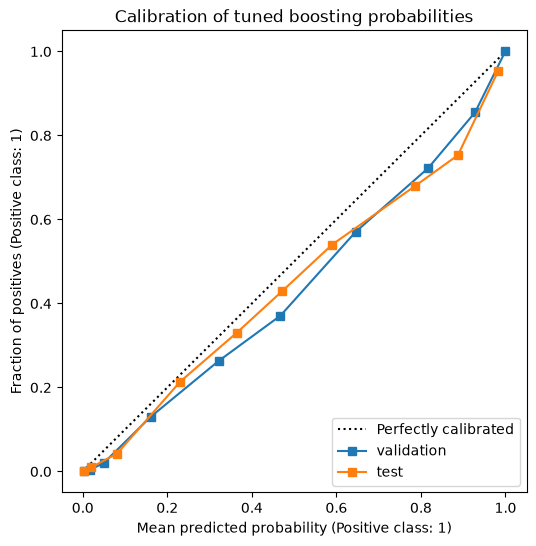

Validation Brier: 0.1153
Test Brier: 0.1405


In [50]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

chosen_pipeline = final_pipeline if "final_pipeline" in globals() else boost_tuned_pipeline
val_p = chosen_pipeline.predict_proba(X_validation)[:, 1]
test_p = chosen_pipeline.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(
    y_validation, val_p, n_bins=10, strategy="quantile",
    name="validation", ax=ax,
)
CalibrationDisplay.from_predictions(
    y_test, test_p, n_bins=10, strategy="quantile",
    name="test", ax=ax,
)
ax.set_title("Calibration of tuned boosting probabilities")
plt.show()

print("Validation Brier:", round(brier_score_loss(y_validation, val_p), 4))
print("Test Brier:", round(brier_score_loss(y_test, test_p), 4))

In [52]:
# Risk tiers are cut on VALIDATION, then frozen for test.
# Low  < 0.30: observed cancel rate ~5% — treat as reliable.
# High >= 0.70: observed cancel rate ~84% — reconfirm / deposit / conservative overbooking.
# Medium is the remainder, near the overall 37–40% base rate.
LOW_RISK_MAX = 0.30
HIGH_RISK_MIN = 0.70


def assign_risk(probability):
    return np.select(
        [probability < LOW_RISK_MAX, probability >= HIGH_RISK_MIN],
        ["low", "high"],
        default="medium",
    )


def tier_summary(y, probability, split):
    y = np.asarray(y)
    tier = assign_risk(probability)
    rows = []
    for label in ["low", "medium", "high"]:
        mask = tier == label
        rows.append({
            "split": split,
            "tier": label,
            "bookings": int(mask.sum()),
            "share": round(mask.mean(), 4),
            "cancel_rate": round(y[mask].mean(), 4),
            "mean_predicted_p": round(probability[mask].mean(), 4),
        })
    return pd.DataFrame(rows)


val_tiers = assign_risk(val_p)
test_tiers = assign_risk(test_p)

tier_table = pd.concat([
    tier_summary(y_validation, val_p, "validation"),
    tier_summary(y_test, test_p, "test"),
], ignore_index=True)
print(tier_table.to_string(index=False))

print("\nHotel actions (frozen from validation):")
print("low    — no extra friction")
print("medium — monitor; optional reminder")
print("high   — reconfirm, request deposit, do not count on the stay for occupancy")

     split   tier  bookings  share  cancel_rate  mean_predicted_p
validation    low      7851 0.4361       0.0534            0.0750
validation medium      4271 0.2372       0.4034            0.4812
validation   high      5882 0.3267       0.8402            0.8997
      test    low      7014 0.3963       0.0646            0.0813
      test medium      5464 0.3087       0.4334            0.4766
      test   high      5221 0.2950       0.7991            0.8884

Hotel actions (frozen from validation):
low    — no extra friction
medium — monitor; optional reminder
high   — reconfirm, request deposit, do not count on the stay for occupancy


                       feature  importance_mean  importance_std
                 country_group         0.092382        0.000998
                  deposit_type         0.086798        0.002332
                   agent_group         0.059388        0.001579
                market_segment         0.054584        0.001830
     total_of_special_requests         0.038596        0.001104
                     lead_time         0.033409        0.001041
   required_car_parking_spaces         0.031469        0.001648
                 customer_type         0.014334        0.000989
previous_bookings_not_canceled         0.005735        0.000280
               booking_changes         0.004149        0.000297
        previous_cancellations         0.002462        0.000329
                  total_nights         0.001769        0.000155
          distribution_channel         0.000723        0.000143
          stays_in_week_nights         0.000378        0.000080
                          meal         0

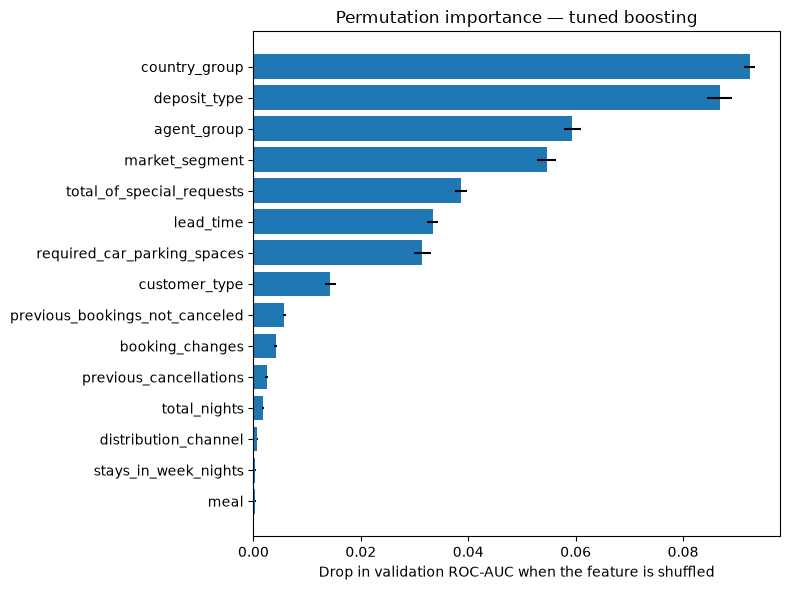

In [53]:
from sklearn.inspection import permutation_importance

chosen_pipeline = final_pipeline if "final_pipeline" in globals() else boost_tuned_pipeline

# Permutation on original booking-time columns, not the one-hot expansion.
# Validation only: this is explanation, not model selection.
perm = permutation_importance(
    chosen_pipeline,
    X_validation,
    y_validation,
    scoring="roc_auc",
    n_repeats=8,
    random_state=42,
    n_jobs=-1,
)

importance = (
    pd.DataFrame({
        "feature": X_validation.columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
print(importance.head(20).to_string(index=False))

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
ax.set_xlabel("Drop in validation ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance — tuned boosting")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_auc_score,
)

chosen_pipeline = final_pipeline if "final_pipeline" in globals() else boost_tuned_pipeline
test_pred = chosen_pipeline.predict(X_test)
test_proba = chosen_pipeline.predict_proba(X_test)[:, 1]

error_frame = X_test.copy()
error_frame["y_true"] = np.asarray(y_test)
error_frame["y_pred"] = test_pred
error_frame["p"] = test_proba
error_frame["false_negative"] = (error_frame["y_true"].eq(1) & error_frame["y_pred"].eq(0)).astype(int)
error_frame["false_positive"] = (error_frame["y_true"].eq(0) & error_frame["y_pred"].eq(1)).astype(int)


def segment_errors(frame, column, min_n=80):
    rows = []
    for value, part in frame.groupby(column, observed=True):
        n = len(part)
        if n < min_n:
            continue
        y = part["y_true"]
        pred = part["y_pred"]
        p = part["p"]
        row = {
            "segment": column,
            "value": value,
            "n": n,
            "cancel_rate": round(y.mean(), 4),
            "predicted_positive_rate": round(pred.mean(), 4),
            "precision": round(precision_score(y, pred, zero_division=0), 4),
            "recall": round(recall_score(y, pred, zero_division=0), 4),
            "fn_rate": round(part["false_negative"].mean(), 4),
            "fp_rate": round(part["false_positive"].mean(), 4),
        }
        if y.nunique() == 2:
            row["roc_auc"] = round(roc_auc_score(y, p), 4)
        else:
            row["roc_auc"] = np.nan
        rows.append(row)
    return pd.DataFrame(rows).sort_values("n", ascending=False)


for column in ["hotel", "market_segment", "country_group", "deposit_type"]:
    table = segment_errors(error_frame, column)
    print(f"\n=== TEST errors by {column} ===")
    print(table.to_string(index=False))